In [60]:
import scipy.io.wavfile as wav
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import copy
from numpy.fft import fft, fftfreq, ifft
from scipy.fft import fftshift

In [61]:
class signal_data: # Class to store signal data
    def __init__(self, filename):
        self.filename = filename
        self.rate, self.data = wav.read(filename)
        self.increment = 1 / self.rate
        self.length = len(self.data)
        self.duration = self.length / self.rate
        self.time = np.arange(0, self.length) / self.rate
        self.freq_max = self.rate / 2
        self.resolution_freq = self.rate / self.length


class delta_signal: # Class to store delta signal data
    def __init__(self, length):
        self.length = length
        self.data = np.zeros(length)
        self.data[0] = 1

def FIR_filter(signal_data, alpha, delay=1):
    # FIR filter implementation using zero padding because the sound signal
    # is finite and not periodic

    filtered_signal = np.zeros(signal_data.length)

    for n in range(signal_data.length):
        if n < delay:
            filtered_signal[n] = signal_data.data[n]
        else:
            filtered_signal[n] = signal_data.data[n] + alpha * signal_data.data[n-delay]

    return filtered_signal

Sampling Rate: 44100 Hz
Signal Length: 237568 samples
Signal Duration: 5.39 seconds


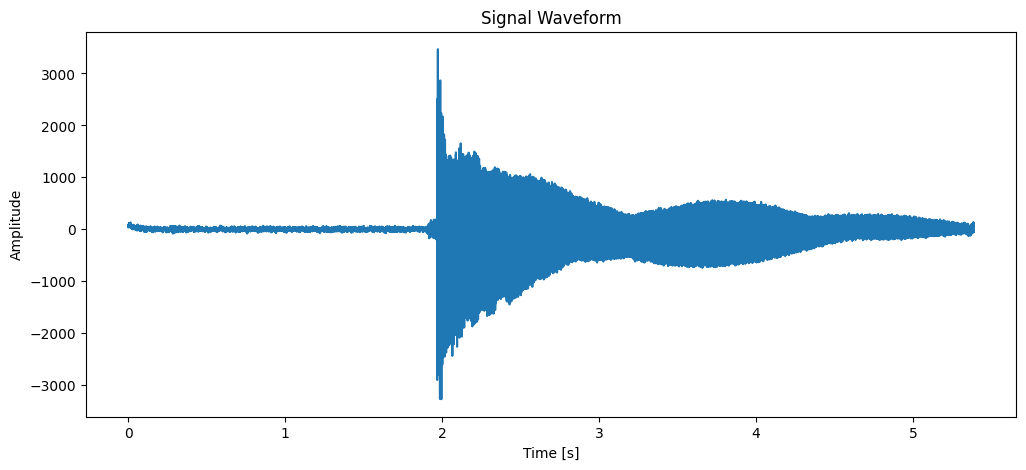

In [62]:
audio_signal = signal_data('data/string_1.wav')
plt.figure(figsize=(12, 5))
sns.lineplot(x=audio_signal.time, y=audio_signal.data)
plt.title('Signal Waveform')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
# relevant information about the signal
print(f"Sampling Rate: {audio_signal.rate} Hz")
print(f"Signal Length: {audio_signal.length} samples")
print(f"Signal Duration: {audio_signal.duration:.2f} seconds")

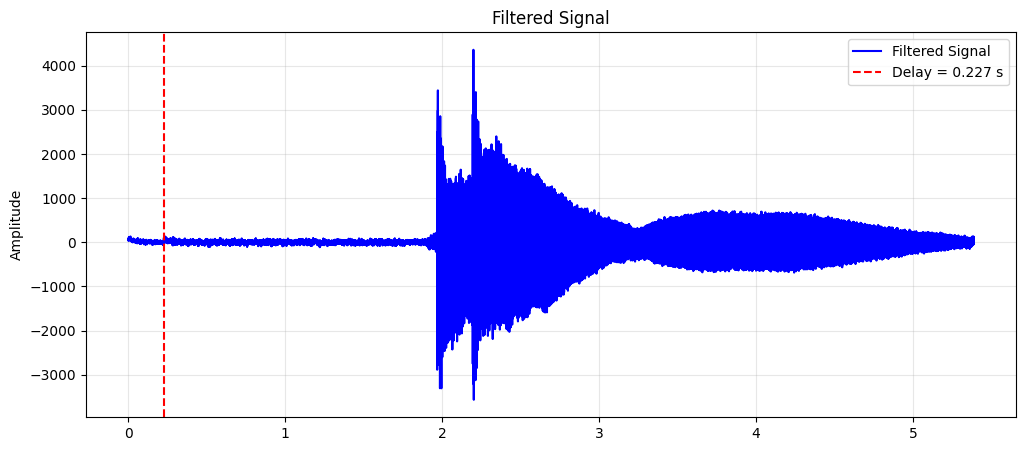

In [63]:
# Apply FIR filter
delay_samples = 10000  # Delay in samples
alpha_value = 0.9  # Feedback coefficient



filtered_signal_data = FIR_filter(
    audio_signal,
    alpha=alpha_value,
    delay=delay_samples
)

seconds_delay= delay_samples * audio_signal.increment

# Plot 1 - Filtered signal
plt.figure(figsize=(12, 5))
sns.lineplot(
    x=audio_signal.time,
    y=filtered_signal_data,
    label='Filtered Signal',
    color='b'
)
plt.axvline(
    x=seconds_delay,
    color='red',
    linestyle='--',
    label=f'Delay = {seconds_delay:.3f} s'
)

plt.title('Filtered Signal')
plt.ylabel('Amplitude')
plt.grid(alpha=0.3)
plt.legend()


Original maximum peak: 3466.00 at 1.9725 s
Filtered maximum peak: 3453.00 at 1.9725 s
Peak time difference: 0.0000 s
Expected FIR delay: 0.2268 s


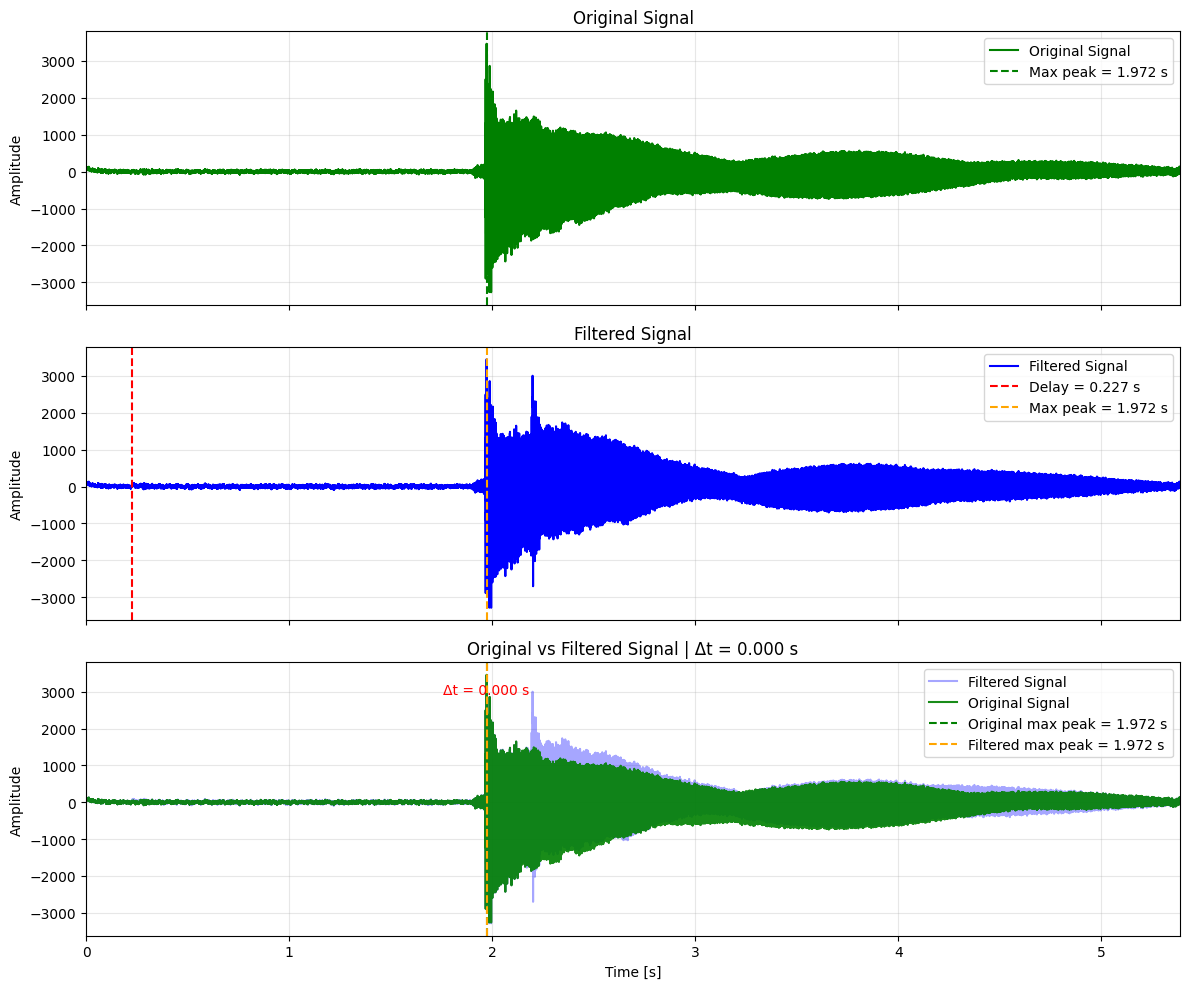

In [64]:
# Apply FIR filter
delay_samples = 10000  # Delay in samples
alpha_value = 0.5  # Feedback coefficient

filtered_signal_data = FIR_filter(
    audio_signal,
    alpha=alpha_value,
    delay=delay_samples
)

seconds_delay= delay_samples * audio_signal.increment
# -------------------------------------------------------------
# Maximum peak of original signal
# -------------------------------------------------------------

max_peak_original_idx = np.argmax(np.abs(audio_signal.data))

max_peak_original_time = audio_signal.time[max_peak_original_idx]

max_peak_original_value = audio_signal.data[max_peak_original_idx]


# -------------------------------------------------------------
# Maximum peak of filtered signal
# -------------------------------------------------------------

max_peak_filtered_idx = np.argmax(np.abs(filtered_signal_data))

max_peak_filtered_time = audio_signal.time[max_peak_filtered_idx]

max_peak_filtered_value = filtered_signal_data[max_peak_filtered_idx]


# -------------------------------------------------------------
# Difference between peaks
# -------------------------------------------------------------

peak_delay = abs(
    max_peak_filtered_time - max_peak_original_time
)


print(
    f"Original maximum peak: {max_peak_original_value:.2f} "
    f"at {max_peak_original_time:.4f} s"
)

print(
    f"Filtered maximum peak: {max_peak_filtered_value:.2f} "
    f"at {max_peak_filtered_time:.4f} s"
)

print(f"Peak time difference: {peak_delay:.4f} s")
print(f"Expected FIR delay: {seconds_delay:.4f} s")

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# Plot 0 - Original signal
sns.lineplot(
    x=audio_signal.time,
    y=audio_signal.data,
    ax=axes[0],
    label='Original Signal',
    color='green'
)

axes[0].axvline(
    x=max_peak_original_time,
    color='g',
    linestyle='--',
    label=f'Max peak = {max_peak_original_time:.3f} s'
)

axes[0].set_title('Original Signal')
axes[0].set_ylabel('Amplitude')
axes[0].grid(alpha=0.3)
axes[0].legend()


# Plot 1 - Filtered signal
sns.lineplot(
    x=audio_signal.time,
    y=filtered_signal_data,
    ax=axes[1],
    label='Filtered Signal',
    color='b'
)
axes[1].axvline(
    x=seconds_delay,
    color='red',
    linestyle='--',
    label=f'Delay = {seconds_delay:.3f} s'
)

axes[1].axvline(
    x=max_peak_filtered_time,
    color='orange',
    linestyle='--',
    label=f'Max peak = {max_peak_filtered_time:.3f} s'
)

axes[1].set_title('Filtered Signal')
axes[1].set_ylabel('Amplitude')
axes[1].grid(alpha=0.3)
axes[1].legend()


# Plot 2 - Original + filtered

sns.lineplot(
    x=audio_signal.time,
    y=filtered_signal_data,
    ax=axes[2],
    label='Filtered Signal',
    color='blue',
    alpha=0.35
)

sns.lineplot(
    x=audio_signal.time,
    y=audio_signal.data,
    ax=axes[2],
    label='Original Signal',
    color='green',
    alpha=0.9
)


axes[2].axvline(
    x=max_peak_original_time,
    color='g',
    linestyle='--',
    label=f'Original max peak = {max_peak_original_time:.3f} s'
)

axes[2].axvline(
    x=max_peak_filtered_time,
    color='orange',
    linestyle='--',
    label=f'Filtered max peak = {max_peak_filtered_time:.3f} s'
)

y_position = np.max(np.abs(audio_signal.data)) * 0.8

axes[2].annotate(
    '',
    xy=(max_peak_filtered_time, y_position),
    xytext=(max_peak_original_time, y_position),
    arrowprops=dict(
        arrowstyle='<->',
        color='red',
        linewidth=2
    )
)

axes[2].text(
    (max_peak_original_time + max_peak_filtered_time) / 2,
    y_position+80,
    f'Δt = {peak_delay:.3f} s',
    color='red',
    ha='center',
    va='bottom'
)

axes[2].set_title(
    f'Original vs Filtered Signal | Δt = {peak_delay:.3f} s'
)

axes[2].set_xlabel('Time [s]')
axes[2].set_ylabel('Amplitude')
axes[2].set_xlim(0, audio_signal.duration)
axes[2].grid(alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()

In [65]:
# save the filtered signal to a new wav file
wav.write('data/string_1_filtered.wav', audio_signal.rate, filtered_signal_data.astype(np.int16))

In [66]:
N = len(audio_signal.data)

delta = delta_signal(N)

impulse_response = FIR_filter(delta, alpha=alpha_value, delay=delay_samples)

print(impulse_response)

# h es un array de length del audio_signal.data, con un 1 en la posición 0 y un 0.5 en la posición 10000, y el resto de posiciones son 0. Esto es lo que se espera de un filtro FIR con alpha=0.5 y delay=10000.
# en otras palabras en el dominio del tiempo tenemos el inicio del audio totaol en 0 y el inicio del audio desfasado con una amplitud de 0.5 en la posicion de delay, y el resto de posiciones son 0. Esto es lo que se espera de un filtro FIR con alpha=0.5 y delay=10000. despues del punto de delay los dos audio se suman y el resultado es el audio original mas el audio desfasado con una amplitud de 0.5.


[1. 0. 0. ... 0. 0. 0.]


Text(0, 0.5, 'Amplitude')

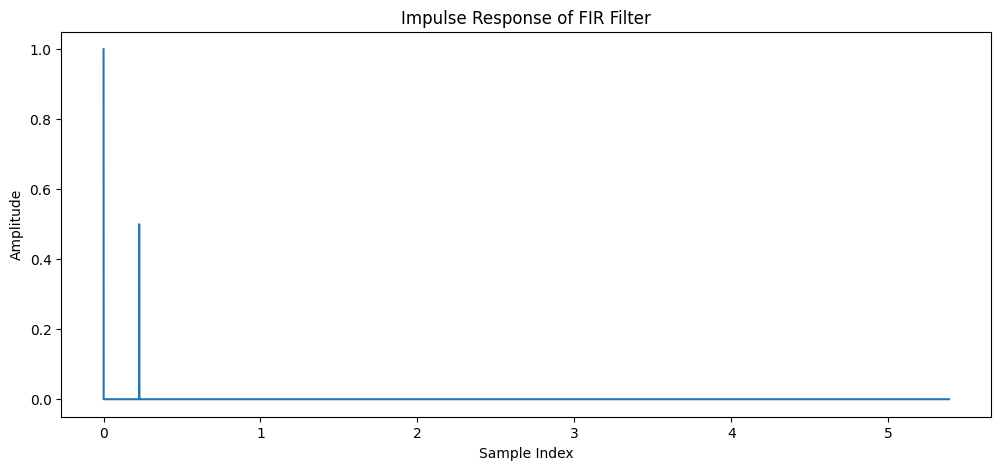

In [67]:
plt.figure(figsize=(12, 5))
sns.lineplot(x=audio_signal.time, y=impulse_response)
plt.title('Impulse Response of FIR Filter')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')

Text(0, 0.5, 'Magnitude')

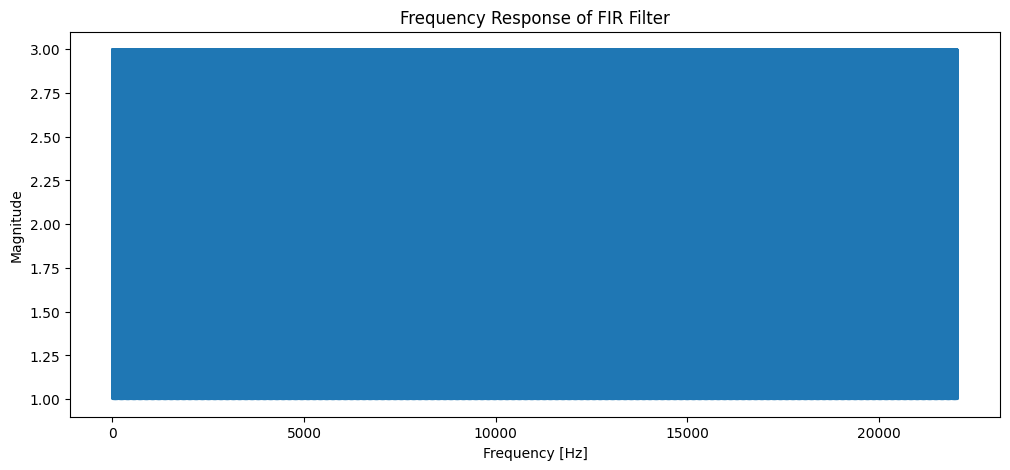

In [68]:
# frequency response of the filter

# 1. Discrete Fourier Transform (DFT)
fft_impulse = fft(impulse_response)
freqs_impulse = fftfreq(len(impulse_response), d=1/audio_signal.rate)

# Centered version (zero in the middle), for a symmetric plot
sig_s1_shift = fftshift(fft_impulse)
f_s1_shift = fftshift(freqs_impulse)
mag_shift = np.abs(sig_s1_shift)

# One-sided version: positive frequencies only
mitad = len(impulse_response) // 2
f_pos = freqs_impulse[:mitad]
mag_pos = 2 * np.abs(fft_impulse[:mitad])

# Plot frequency response
plt.figure(figsize=(12, 5))
sns.lineplot(x=f_pos, y=mag_pos)
plt.title('Frequency Response of FIR Filter')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude')


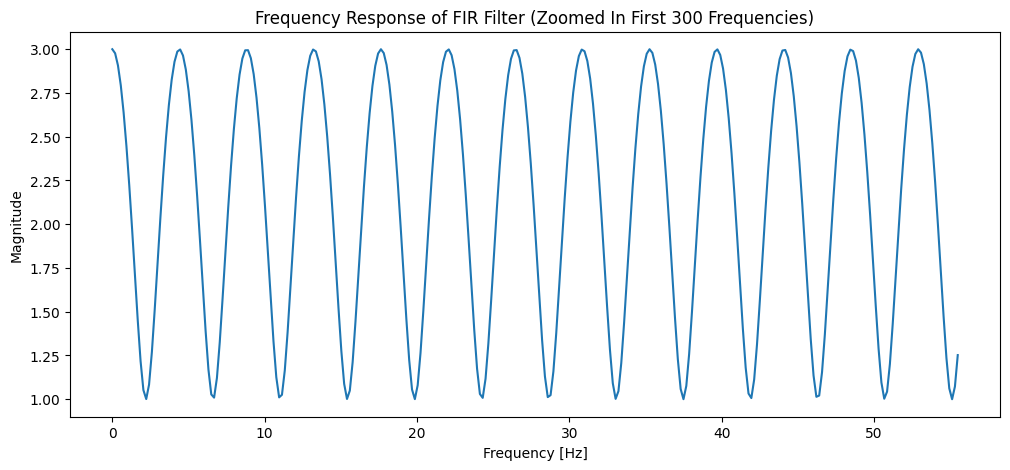

In [69]:

plt.figure(figsize=(12, 5))
sns.lineplot(x=f_pos[0:300], y=mag_pos[0:300])
plt.title('Frequency Response of FIR Filter (Zoomed In First 300 Frequencies)')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude')
plt.show()

In [70]:
# we know that the filtred sound can be obtained by the convolution of the original sound with the impulse response of the filter.
#  In the frequency domain, this is equivalent to multiplying the Fourier transforms of both signals. 
# Therefore, we can check if the filtered signal obtained by applying the FIR filter is equal to the convolution of the original signal with the impulse response of the filter.

237568
237568


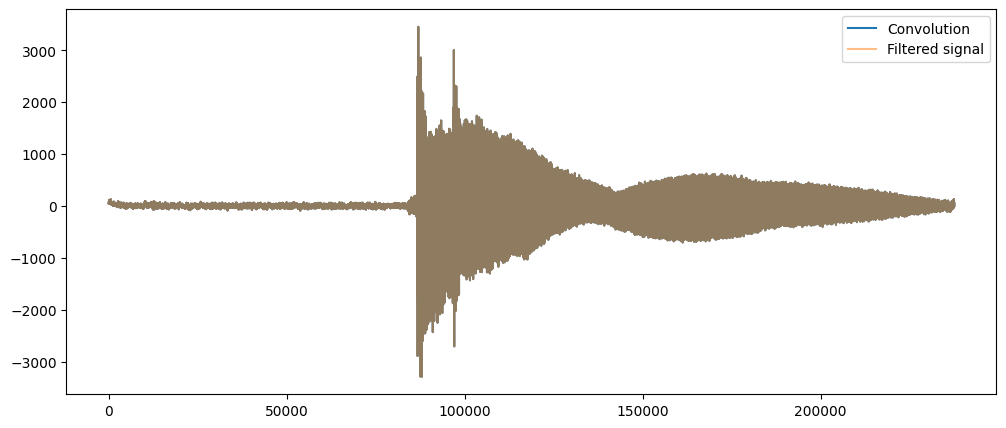

In [71]:
from scipy.signal import fftconvolve

# Full convolution
conv_full = fftconvolve(
    audio_signal.data,
    impulse_response,
    mode="full" # we have used full to be able to obtain a linear convolution with the requirement of Lx + Lh - 1
)

# Keep the causal part corresponding to the original signal
conv_signal = conv_full[:len(audio_signal.data)]

print(len(conv_signal))
print(len(filtered_signal_data))

plt.figure(figsize=(12, 5))
plt.plot(conv_signal, label="Convolution")
plt.plot(filtered_signal_data, label="Filtered signal", alpha=0.5)
plt.legend()
plt.show()

In [72]:
print(f'Is the filtered signal equal to the convolution? {np.allclose(conv_signal, filtered_signal_data)}')

Is the filtered signal equal to the convolution? True


Length of original signal: 237568
Length of impulse response: 237568
Length required for linear convolution: 475135
Length of padded signal: 475135
Length of padded impulse response: 475135


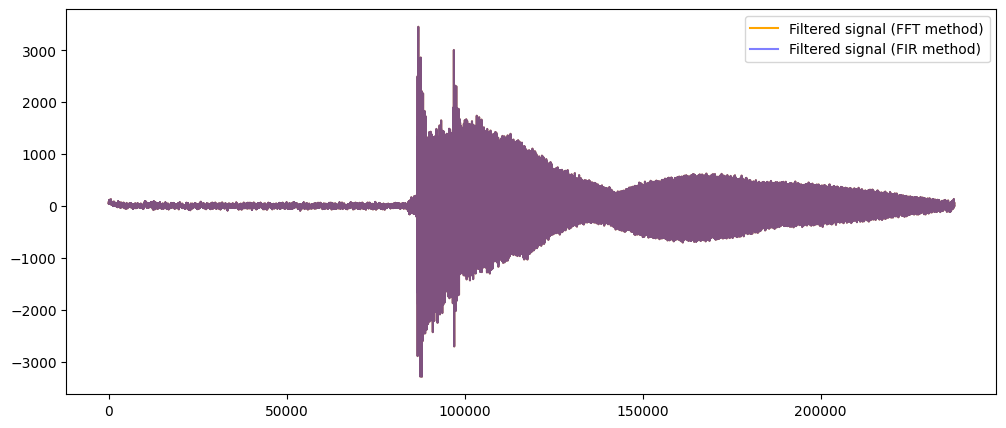

Is the filtered signal equal to the filtered signal using the FFT method? True


In [75]:
# Length required for linear convolution
print(f"Length of original signal: {len(audio_signal.data)}")
print(f"Length of impulse response: {len(impulse_response)}")

N = 2 * audio_signal.length - 1
print(f"Length required for linear convolution: {N}")

# Amount of zero-padding needed
N_padding = N - len(audio_signal.data)

# Zero-padding
audio_signal_padded = np.pad(
    audio_signal.data,
    (0, N_padding),
    mode='constant'
)

impulse_response_padded = np.pad(
    impulse_response,
    (0, N_padding),
    mode='constant'
)

print(f"Length of padded signal: {len(audio_signal_padded)}")
print(f"Length of padded impulse response: {len(impulse_response_padded)}")

# FFT
audio_signal_fft = fft(audio_signal_padded)
impulse_response_fft = fft(impulse_response_padded)

# Multiplication in frequency domain
audio_signal_filtered_fft = (
    audio_signal_fft * impulse_response_fft
)

# Back to time domain
audio_signal_filtered_fftmethod = np.real(
    ifft(audio_signal_filtered_fft)
)[0:len(audio_signal.data)]  # Keep only the causal part corresponding to the original signal

# Compare
plt.figure(figsize=(12, 5))

plt.plot(
    audio_signal_filtered_fftmethod,
    label="Filtered signal (FFT method)",
    color='orange'
)

plt.plot(
    filtered_signal_data,
    label="Filtered signal (FIR method)",
    alpha=0.5,
    color='blue'
)

plt.legend()
plt.show()

print(f'Is the filtered signal equal to the filtered signal using the FFT method? {np.allclose(audio_signal_filtered_fftmethod, filtered_signal_data)}')